Bert embeddings

In [37]:
from sentence_transformers import SentenceTransformer

bert_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

print("Embedding dimensions:", bert_model.get_sentence_embedding_dimension())
print("Maximum sequence length:", bert_model.max_seq_length)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding dimensions: 384
Maximum sequence length: 256


/var/folders/z3/0j97vknj4696wz9q6_jg32240000gn/T/ipykernel_89052/3247322341.py:7: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Embedding dimensions:", bert_model.get_sentence_embedding_dimension())


In [38]:
from pathlib import Path
import pandas as pd

# Find all book and movie files
book_files = sorted(Path("../book_data").glob("book*_dialogue.csv"))
movie_files = sorted(Path("../movie_data").glob("hp*.csv"))

print("Book files:", len(book_files))
print("Movie files:", len(movie_files))


def load_files(files, version):

    frames = []

    for file in files:
        temp = pd.read_csv(file)

        temp["version"] = version
        temp["source_file"] = file.stem

        frames.append(temp)

    return pd.concat(frames, ignore_index=True)


books = load_files(book_files, "book")
movies = load_files(movie_files, "movie")

# Combine all dialogue
df = pd.concat([books, movies], ignore_index=True)

print(df.groupby("version").size())

Book files: 7
Movie files: 8
version
book     35550
movie     7445
dtype: int64


In [39]:
import pandas as pd
import numpy as np

df["version"] = (
    df["version"]
    .str.lower()
    .replace({"film": "movie"})
)

df["dialog"] = df["dialog"].fillna("").astype(str)

# Remove empty dialogue
df = df[df["dialog"].str.strip() != ""].copy()

# Count words per dialogue
df["word_count"] = df["dialog"].str.split().str.len()

In [40]:
character_dialogues = (
    df.groupby(["version", "character"], sort=False)["dialog"]
    .apply(list)
    .to_dict()
)

print("Number of character/version combinations:", len(character_dialogues))

Number of character/version combinations: 284


In [41]:
tokenizer = bert_model.tokenizer
max_length = bert_model.max_seq_length

def split_long_utterance(text):

    # Count actual model tokens, including special tokens
    token_count = len(
        tokenizer(
            text,
            add_special_tokens=True,
            truncation=False
        )["input_ids"]
    )

    # The utterance fits the model
    if token_count <= max_length:
        return [text]

    # If too long, split at word boundaries
    words = text.split()

    if len(words) <= 1:
        return [text]

    midpoint = len(words) // 2

    left = " ".join(words[:midpoint])
    right = " ".join(words[midpoint:])

    return (
        split_long_utterance(left)
        + split_long_utterance(right)
    )

In [42]:
from numpy.linalg import norm

bert_character_embeddings = {}

character_chunk_counts = {}

for key, dialogues in character_dialogues.items():

    # 1. Split long utterances if necessary
    passages = []

    for dialogue in dialogues:
        passages.extend(
            split_long_utterance(dialogue)
        )

    if not passages:
        continue

    # 2. Encode all passages
    passage_embeddings = bert_model.encode(
        passages,
        batch_size=32,
        show_progress_bar=False,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    # 3. Calculate token count for each passage
    weights = np.array([
        len(tokenizer.encode(
            passage,
            add_special_tokens=False
        ))
        for passage in passages
    ], dtype=float)

    weights = np.maximum(weights, 1)

    # 4. Weighted average of passage embeddings
    character_embedding = np.average(
        passage_embeddings,
        axis=0,
        weights=weights
    )

    # 5. Normalize the final character embedding
    embedding_norm = norm(character_embedding)

    if embedding_norm > 0:
        character_embedding /= embedding_norm

    bert_character_embeddings[key] = character_embedding

    character_chunk_counts[key] = len(passages)


print("Number of character embeddings:", len(bert_character_embeddings))

print(
    "Embedding dimensions:",
    next(iter(bert_character_embeddings.values())).shape
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (266 > 256). Running this sequence through the model will result in indexing errors


Number of character embeddings: 284
Embedding dimensions: (384,)


In [43]:
from sklearn.metrics.pairwise import cosine_similarity

def get_top_characters(version, n):

    counts = (
        df[df["version"] == version]
        .groupby("character")["word_count"]
        .sum()
        .sort_values(ascending=False)
    )

    return counts.head(n)

In [44]:
def get_bert_similarity(version, top_n=30):

    top_characters = get_top_characters(version, top_n)

    characters = [
        c for c in top_characters.index
        if (version, c) in bert_character_embeddings
    ]

    # Stack embeddings into a matrix
    X = np.vstack([
        bert_character_embeddings[(version, c)]
        for c in characters
    ])

    # Pairwise cosine similarity
    similarity = cosine_similarity(X)

    similarity_df = pd.DataFrame(
        similarity,
        index=characters,
        columns=characters
    )

    # Print statistics excluding diagonal
    values = similarity[
        np.triu_indices(len(characters), k=1)
    ]

    print(f"\n{version.upper()} SIMILARITIES")
    print("Mean:", round(values.mean(), 3))
    print("Median:", round(np.median(values), 3))
    print("Minimum:", round(values.min(), 3))
    print("Maximum:", round(values.max(), 3))

    return similarity_df


BOOK SIMILARITIES
Mean: 0.872
Median: 0.892
Minimum: 0.593
Maximum: 0.988


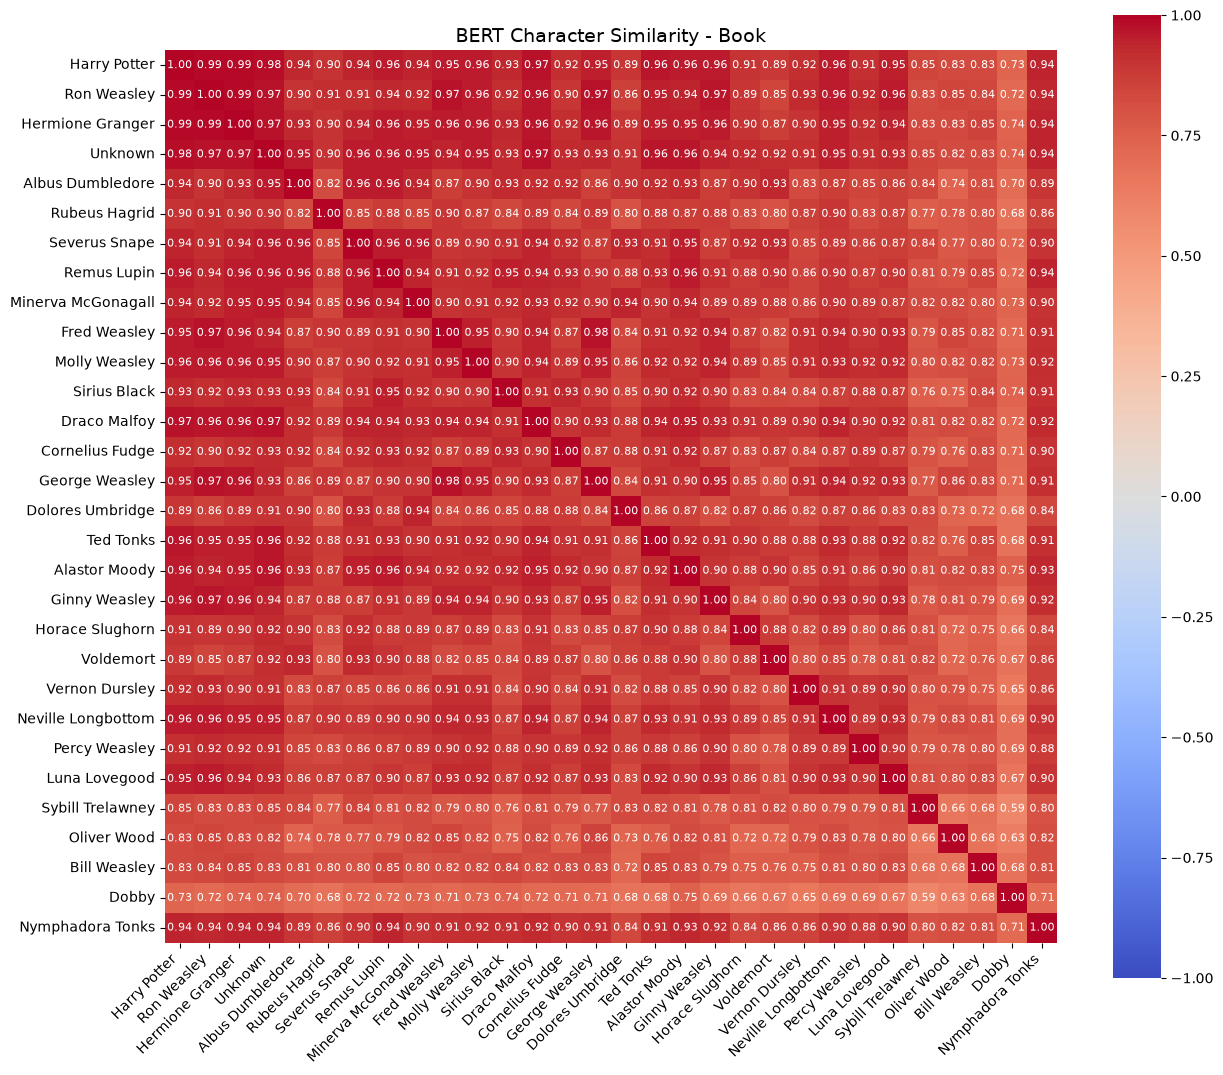


MOVIE SIMILARITIES
Mean: 0.8
Median: 0.828
Minimum: 0.386
Maximum: 0.97


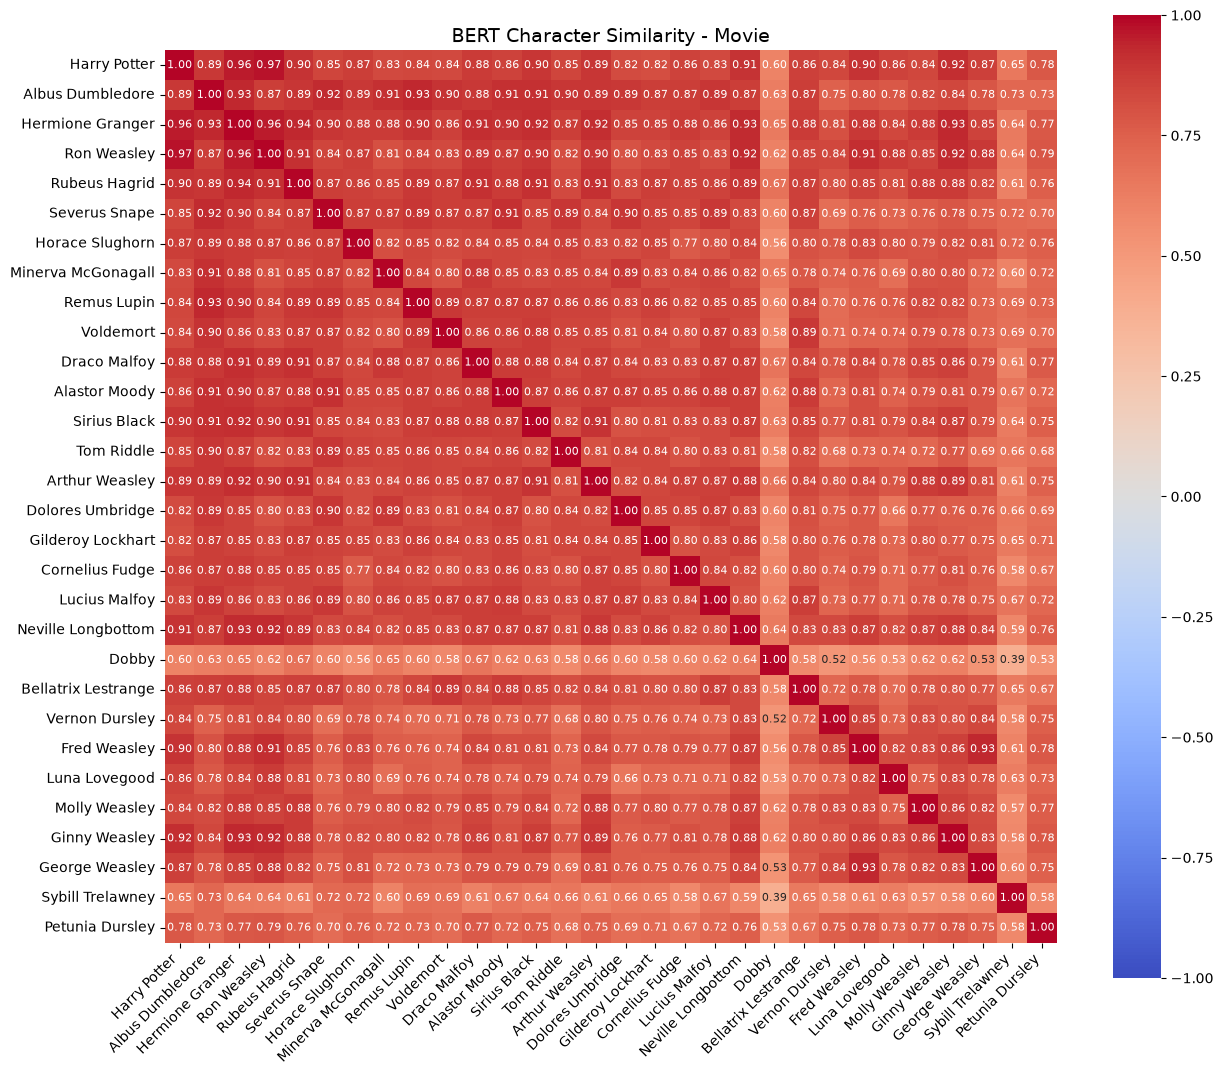

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_bert_heatmap(similarity_df, version):

    plt.figure(figsize=(13, 11))

    sns.heatmap(
        similarity_df,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 8},
        square=True
    )

    plt.title(
        f"BERT Character Similarity - {version.capitalize()}",
        fontsize=14
    )

    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()


# Books
book_bert_similarity = get_bert_similarity("book")
plot_bert_heatmap(book_bert_similarity, "book")

# Movies
movie_bert_similarity = get_bert_similarity("movie")
plot_bert_heatmap(movie_bert_similarity, "movie")

In [46]:
from sklearn.decomposition import PCA

# Collect top 20 characters from both versions
selected_keys = []

for version in ["book", "movie"]:

    top = get_top_characters(version, 20)

    for character in top.index:

        key = (version, character)

        if key in bert_character_embeddings:
            selected_keys.append(key)


# Create embedding matrix
X = np.vstack([
    bert_character_embeddings[key]
    for key in selected_keys
])

# Apply PCA
pca = PCA(n_components=2, random_state=42)

X_2d = pca.fit_transform(X)

print("Explained variance by PC1 and PC2:")
print(pca.explained_variance_ratio_)

print("Total explained variance:")
print(pca.explained_variance_ratio_.sum())

Explained variance by PC1 and PC2:
[0.20496641 0.11545172]
Total explained variance:
0.3204181292472252


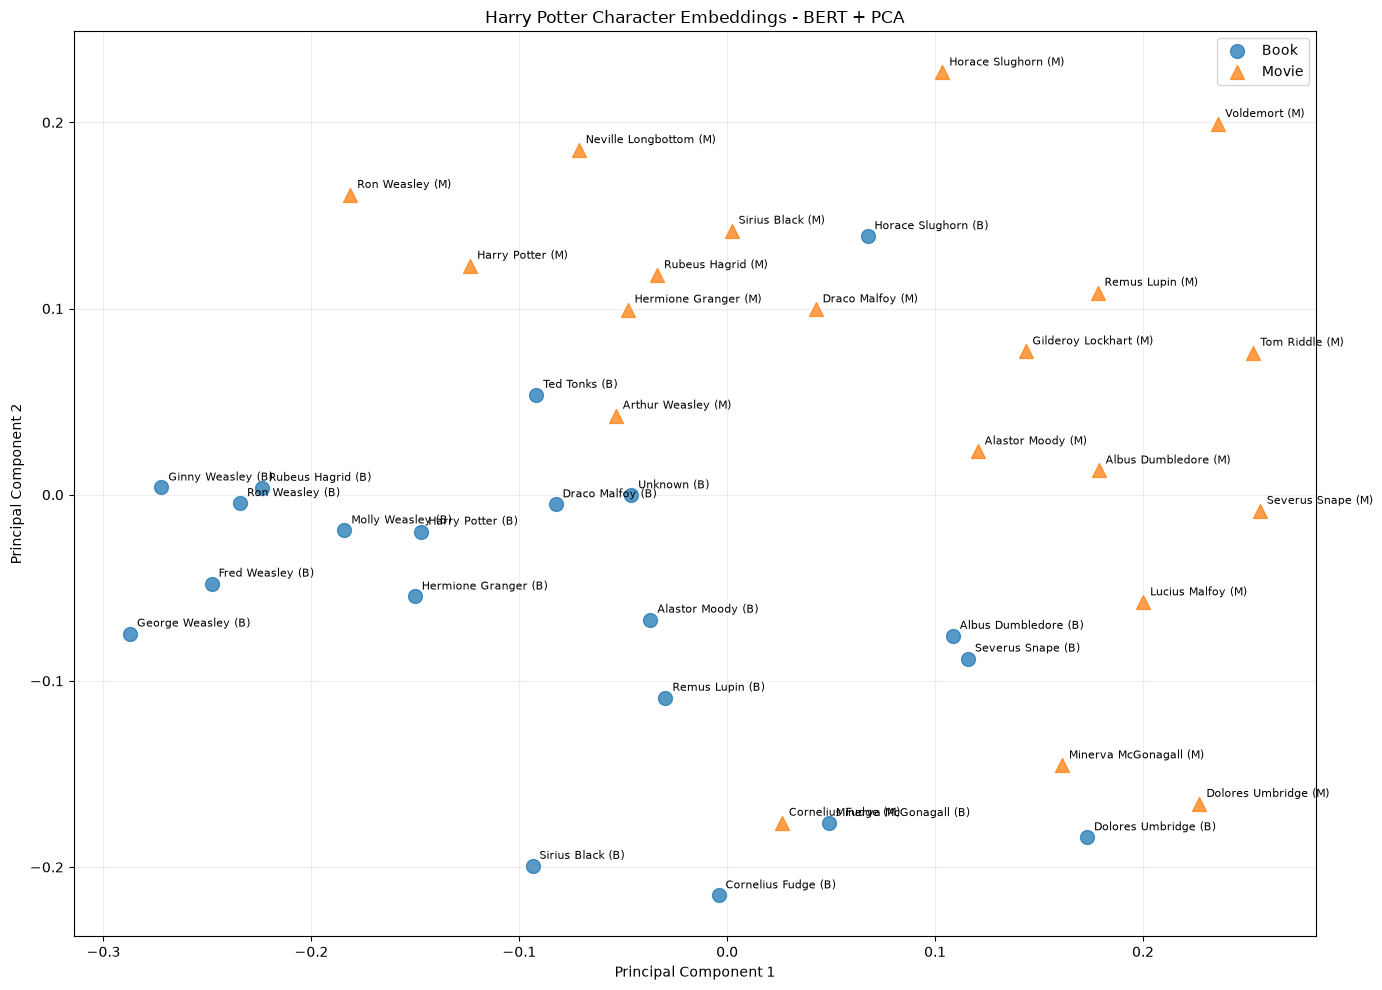

In [47]:
plot_df = pd.DataFrame({
    "character": [key[1] for key in selected_keys],
    "version": [key[0] for key in selected_keys],
    "PC1": X_2d[:, 0],
    "PC2": X_2d[:, 1]
})

plt.figure(figsize=(14, 10))

for version, marker in [
    ("book", "o"),
    ("movie", "^")
]:

    subset = plot_df[
        plot_df["version"] == version
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=version.capitalize(),
        marker=marker,
        s=100,
        alpha=0.75
    )

    for _, row in subset.iterrows():

        plt.annotate(
            f"{row['character']} ({row['version'][0].upper()})",
            (row["PC1"], row["PC2"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

plt.title("Harry Potter Character Embeddings - BERT + PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [62]:
# Make sure version names are consistent
df["version"] = df["version"].str.lower().replace({
    "film": "movie"
})

# Calculate dialogue word counts
df["word_count"] = (
    df["dialog"].fillna("").astype(str).str.split().str.len()
)

# Total dialogue words per movie character
movie_counts = (
    df[df["version"] == "movie"]
    .groupby("character")["word_count"]
    .sum()
    .sort_values(ascending=False)
)

# Find characters that have embeddings in BOTH versions
common_characters = [
    character
    for character in movie_counts.index
    if (
        ("movie", character) in bert_character_embeddings
        and ("book", character) in bert_character_embeddings
    )
]

# Select top 25, ranked by movie dialogue volume
selected_characters = common_characters[:30]

print("Selected characters:")
for i, character in enumerate(selected_characters, 1):
    print(i, character, movie_counts[character])

print("\nNumber of selected characters:", len(selected_characters))

Selected characters:
1 Harry Potter 13970
2 Albus Dumbledore 7653
3 Hermione Granger 7634
4 Ron Weasley 6916
5 Rubeus Hagrid 3473
6 Severus Snape 2381
7 Horace Slughorn 2194
8 Minerva McGonagall 1962
9 Remus Lupin 1902
10 Voldemort 1712
11 Draco Malfoy 1275
12 Alastor Moody 1196
13 Sirius Black 1082
14 Dolores Umbridge 958
15 Gilderoy Lockhart 887
16 Cornelius Fudge 782
17 Lucius Malfoy 770
18 Neville Longbottom 761
19 Dobby 727
20 Bellatrix Lestrange 689
21 Vernon Dursley 679
22 Fred Weasley 599
23 Luna Lovegood 553
24 Molly Weasley 543
25 Ginny Weasley 505
26 George Weasley 483
27 Sybill Trelawney 439
28 Petunia Dursley 397
29 Bartemius Crouch 354
30 Rufus Scrimgeour 339

Number of selected characters: 30


In [63]:
import numpy as np
import pandas as pd

from sklearn.metrics.pairwise import cosine_similarity

# Create book embedding matrix
book_X = np.vstack([
    bert_character_embeddings[("book", character)]
    for character in selected_characters
])

# Create movie embedding matrix
movie_X = np.vstack([
    bert_character_embeddings[("movie", character)]
    for character in selected_characters
])

# Calculate similarities independently
book_similarity = cosine_similarity(book_X)
movie_similarity = cosine_similarity(movie_X)

# Convert to DataFrames
book_similarity_df = pd.DataFrame(
    book_similarity,
    index=selected_characters,
    columns=selected_characters
)

movie_similarity_df = pd.DataFrame(
    movie_similarity,
    index=selected_characters,
    columns=selected_characters
)

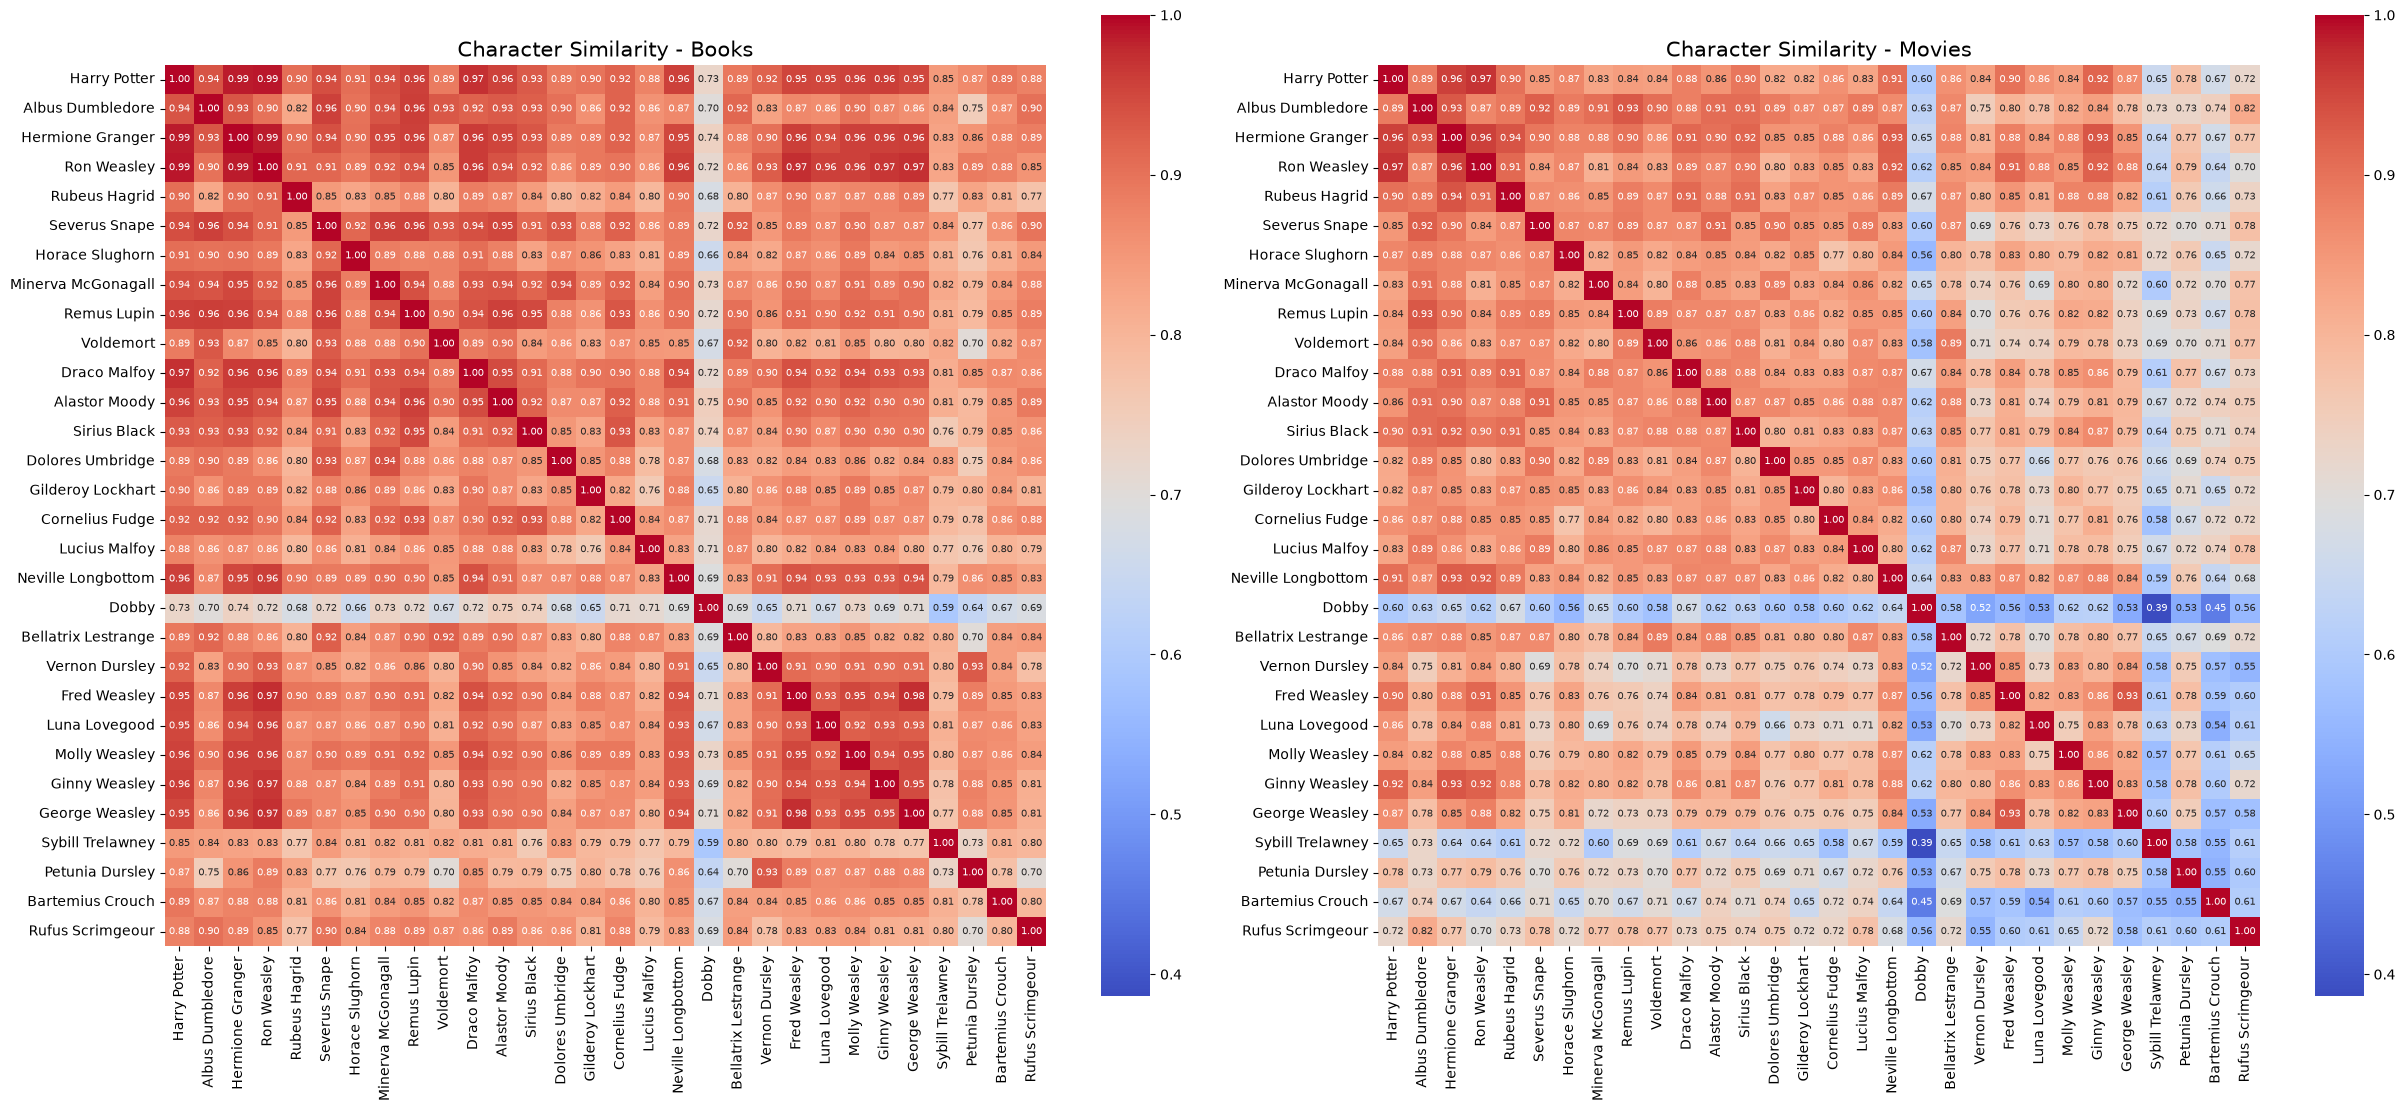

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

# Use the same colour range for both heatmaps
vmin = min(book_similarity.min(), movie_similarity.min())
vmax = max(book_similarity.max(), movie_similarity.max())

fig, axes = plt.subplots(1, 2, figsize=(25, 11))

# Book heatmap
sns.heatmap(
    book_similarity_df,
    ax=axes[0],
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    square=True
)

axes[0].set_title("Character Similarity - Books", fontsize=15)
axes[0].tick_params(axis="x", rotation=90)
axes[0].tick_params(axis="y", rotation=0)

# Movie heatmap
sns.heatmap(
    movie_similarity_df,
    ax=axes[1],
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    square=True
)

axes[1].set_title("Character Similarity - Movies", fontsize=15)
axes[1].tick_params(axis="x", rotation=90)
axes[1].tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

In [65]:
%pip install annoy

Note: you may need to restart the kernel to use updated packages.


In [66]:
from annoy import AnnoyIndex
print("Annoy installed successfully")

Annoy installed successfully


In [67]:
import pacmap
import numpy as np
from sklearn.preprocessing import normalize

# Prepare embeddings
X_combined = np.vstack([
    book_X,
    movie_X
])

X_combined = normalize(X_combined, norm="l2")
X_combined = np.ascontiguousarray(
    X_combined, dtype=np.float32
)

# PaCMAP using Annoy instead of FAISS
reducer = pacmap.PaCMAP(
    n_components=2,
    n_neighbors=5,
    MN_ratio=0.5,
    FP_ratio=1.0,
    knn_backend="annoy",
    verbose=True,
    random_state=42
)

# Project into 2D
X_pacmap = reducer.fit_transform(
    X_combined,
    init="pca"
)

print("Result shape:", X_pacmap.shape)

Applied PCA, the dimensionality becomes 100
PaCMAP(n_neighbors=5, n_MN=2, n_FP=5, distance=euclidean, lr=1.0, n_iters=(100, 100, 250), apply_pca=True, opt_method='adam', verbose=True, intermediate=False, seed=42, knn_backend=annoy)
Finding pairs
Found nearest neighbor
Calculated sigma
Found scaled dist
Pairs sampled successfully.
((300, 2), (120, 2), (300, 2))
Initial Loss: 216.5438690185547
Iteration:   10, Loss: 188.782318
Iteration:   20, Loss: 169.967987
Iteration:   30, Loss: 163.101288
Iteration:   40, Loss: 158.148102
Iteration:   50, Loss: 154.086273
Iteration:   60, Loss: 150.134735
Iteration:   70, Loss: 145.972595
Iteration:   80, Loss: 141.428040
Iteration:   90, Loss: 136.246780
Iteration:  100, Loss: 129.844147
Iteration:  110, Loss: 169.372406
Iteration:  120, Loss: 169.034744
Iteration:  130, Loss: 168.916046
Iteration:  140, Loss: 168.877579
Iteration:  150, Loss: 168.859940
Iteration:  160, Loss: 168.859161
Iteration:  170, Loss: 168.864792
Iteration:  180, Loss: 168.

In [68]:
import pacmap
import inspect
import sys

print("Version:", pacmap.__version__)
print("Package location:", pacmap.__file__)
print("Python:", sys.executable)

print("\nSupported parameters:")
print(inspect.signature(pacmap.PaCMAP))

Version: 0.9.1
Package location: /Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/pacmap/__init__.py
Python: /usr/local/bin/python3.11

Supported parameters:
(n_components=2, n_neighbors=10, MN_ratio=0.5, FP_ratio=2.0, pair_neighbors=None, pair_MN=None, pair_FP=None, distance='euclidean', lr=1.0, num_iters=(100, 100, 250), verbose=False, apply_pca=True, intermediate=False, intermediate_snapshots=[0, 10, 30, 60, 100, 120, 140, 170, 200, 250, 300, 350, 450], random_state=None, save_tree=False, knn_backend='faiss')


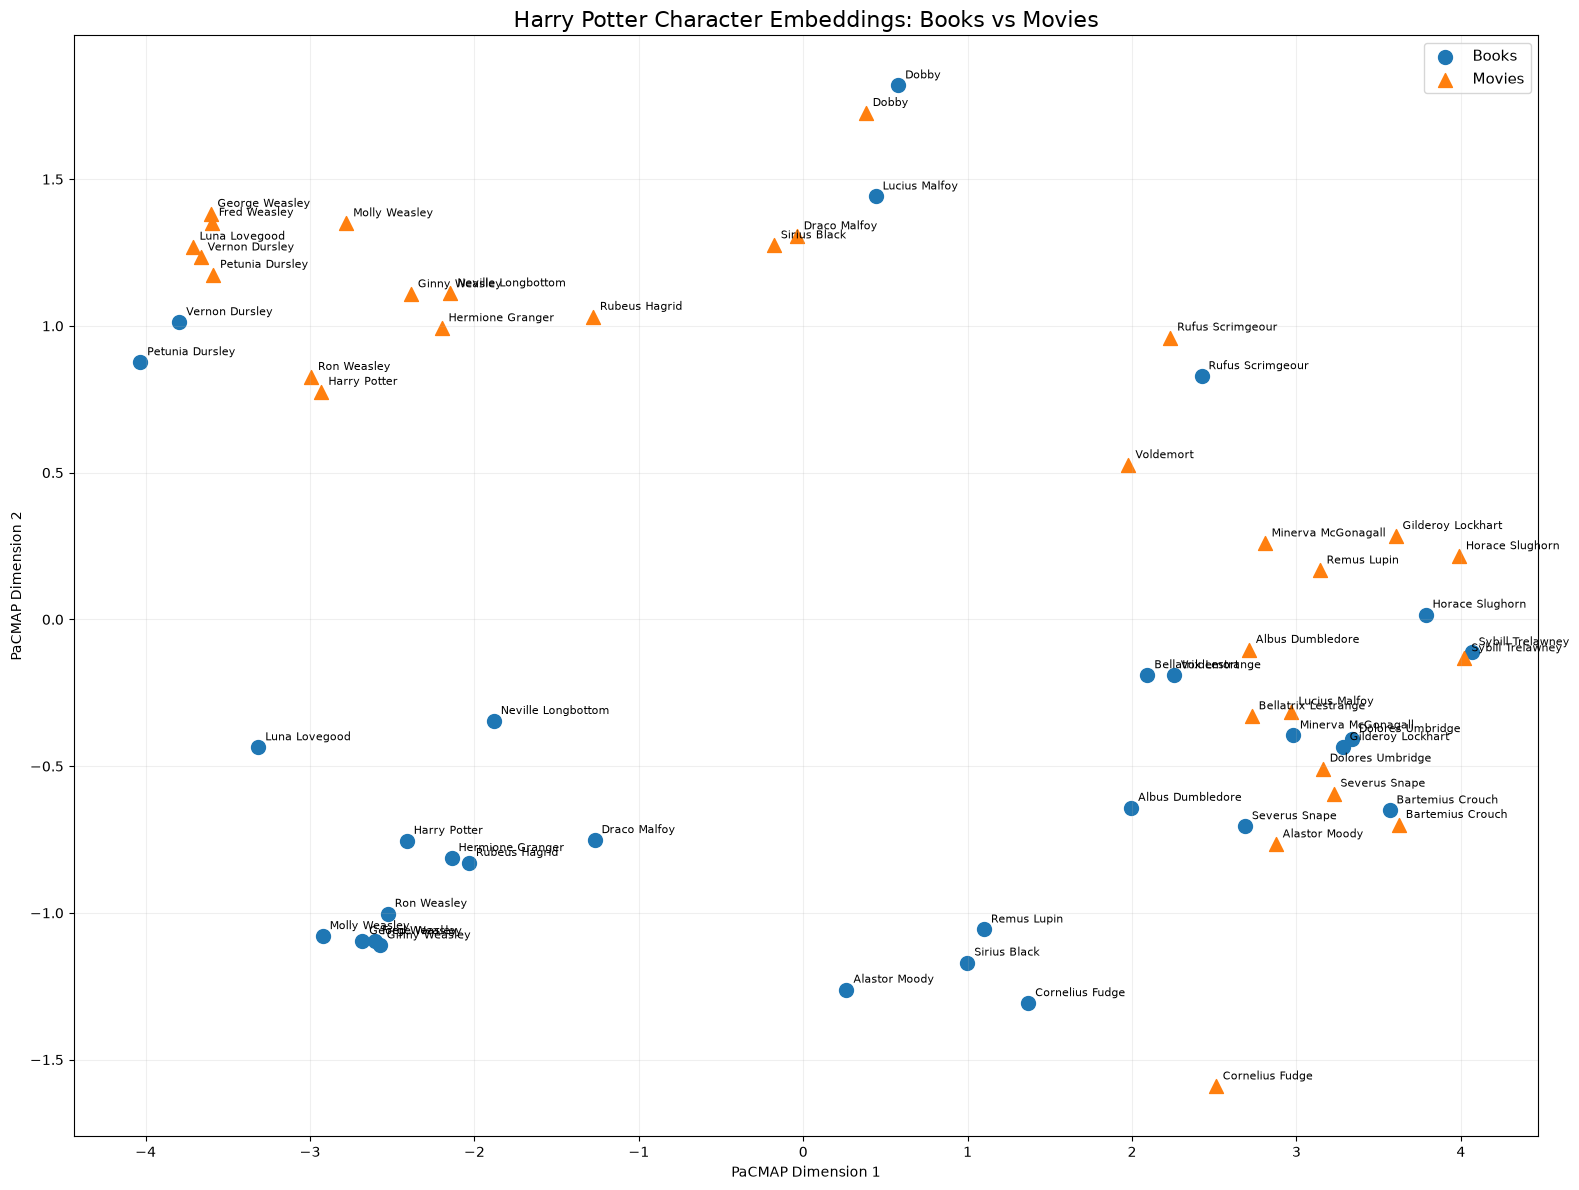

In [69]:
import matplotlib.pyplot as plt
import numpy as np

n = len(selected_characters)

# Separate book and movie coordinates
book_coordinates = X_pacmap[:n]
movie_coordinates = X_pacmap[n:]

# Create figure
plt.figure(figsize=(16, 12))

# # Draw lines connecting the same characters
# for i, character in enumerate(selected_characters):

#     plt.plot(
#         [book_coordinates[i, 0], movie_coordinates[i, 0]],
#         [book_coordinates[i, 1], movie_coordinates[i, 1]],
#         linestyle="--",
#         alpha=0.35,
#         linewidth=1
#     )

# Plot book embeddings
plt.scatter(
    book_coordinates[:, 0],
    book_coordinates[:, 1],
    marker="o",
    s=100,
    label="Books"
)

# Plot movie embeddings
plt.scatter(
    movie_coordinates[:, 0],
    movie_coordinates[:, 1],
    marker="^",
    s=100,
    label="Movies"
)

# Add character labels directly at their projected positions
for i, character in enumerate(selected_characters):

    # Book label
    plt.annotate(
        character,
        book_coordinates[i],
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

    # Movie label
    plt.annotate(
        character,
        movie_coordinates[i],
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.title(
    "Harry Potter Character Embeddings: Books vs Movies",
    fontsize=16
)

plt.xlabel("PaCMAP Dimension 1")
plt.ylabel("PaCMAP Dimension 2")

plt.legend(fontsize=11)
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

Villain analysis

In [72]:
villains = [
    "Voldemort",
    "Bellatrix Lestrange",
    "Dolores Umbridge",
    "Lucius Malfoy",
    "Bartemius Crouch"
]

ambiguous = [
    "Severus Snape",
    "Draco Malfoy",
    "Horace Slughorn",
    "Gilderoy Lockhart",
    "Cornelius Fudge",
    "Vernon Dursley",
    "Petunia Dursley",
    "Rufus Scrimgeour"
]

non_villains = [
    "Harry Potter",
    "Albus Dumbledore",
    "Hermione Granger",
    "Ron Weasley",
    "Rubeus Hagrid",
    "Minerva McGonagall",
    "Remus Lupin",
    "Alastor Moody",
    "Sirius Black",
    "Neville Longbottom",
    "Dobby",
    "Fred Weasley",
    "Luna Lovegood",
    "Molly Weasley",
    "Ginny Weasley",
    "George Weasley",
    "Sybill Trelawney"
]

# Villains first, ambiguous second, non-villains last
ordered_characters = villains + ambiguous + non_villains

# Check that all selected characters are accounted for
assert set(ordered_characters) == set(selected_characters)
assert len(ordered_characters) == len(set(ordered_characters))

print(f"Villains: {len(villains)}")
print(f"Ambiguous: {len(ambiguous)}")
print(f"Non-villains: {len(non_villains)}")
print(f"Total: {len(ordered_characters)}")

print(ordered_characters)

Villains: 5
Ambiguous: 8
Non-villains: 17
Total: 30
['Voldemort', 'Bellatrix Lestrange', 'Dolores Umbridge', 'Lucius Malfoy', 'Bartemius Crouch', 'Severus Snape', 'Draco Malfoy', 'Horace Slughorn', 'Gilderoy Lockhart', 'Cornelius Fudge', 'Vernon Dursley', 'Petunia Dursley', 'Rufus Scrimgeour', 'Harry Potter', 'Albus Dumbledore', 'Hermione Granger', 'Ron Weasley', 'Rubeus Hagrid', 'Minerva McGonagall', 'Remus Lupin', 'Alastor Moody', 'Sirius Black', 'Neville Longbottom', 'Dobby', 'Fred Weasley', 'Luna Lovegood', 'Molly Weasley', 'Ginny Weasley', 'George Weasley', 'Sybill Trelawney']


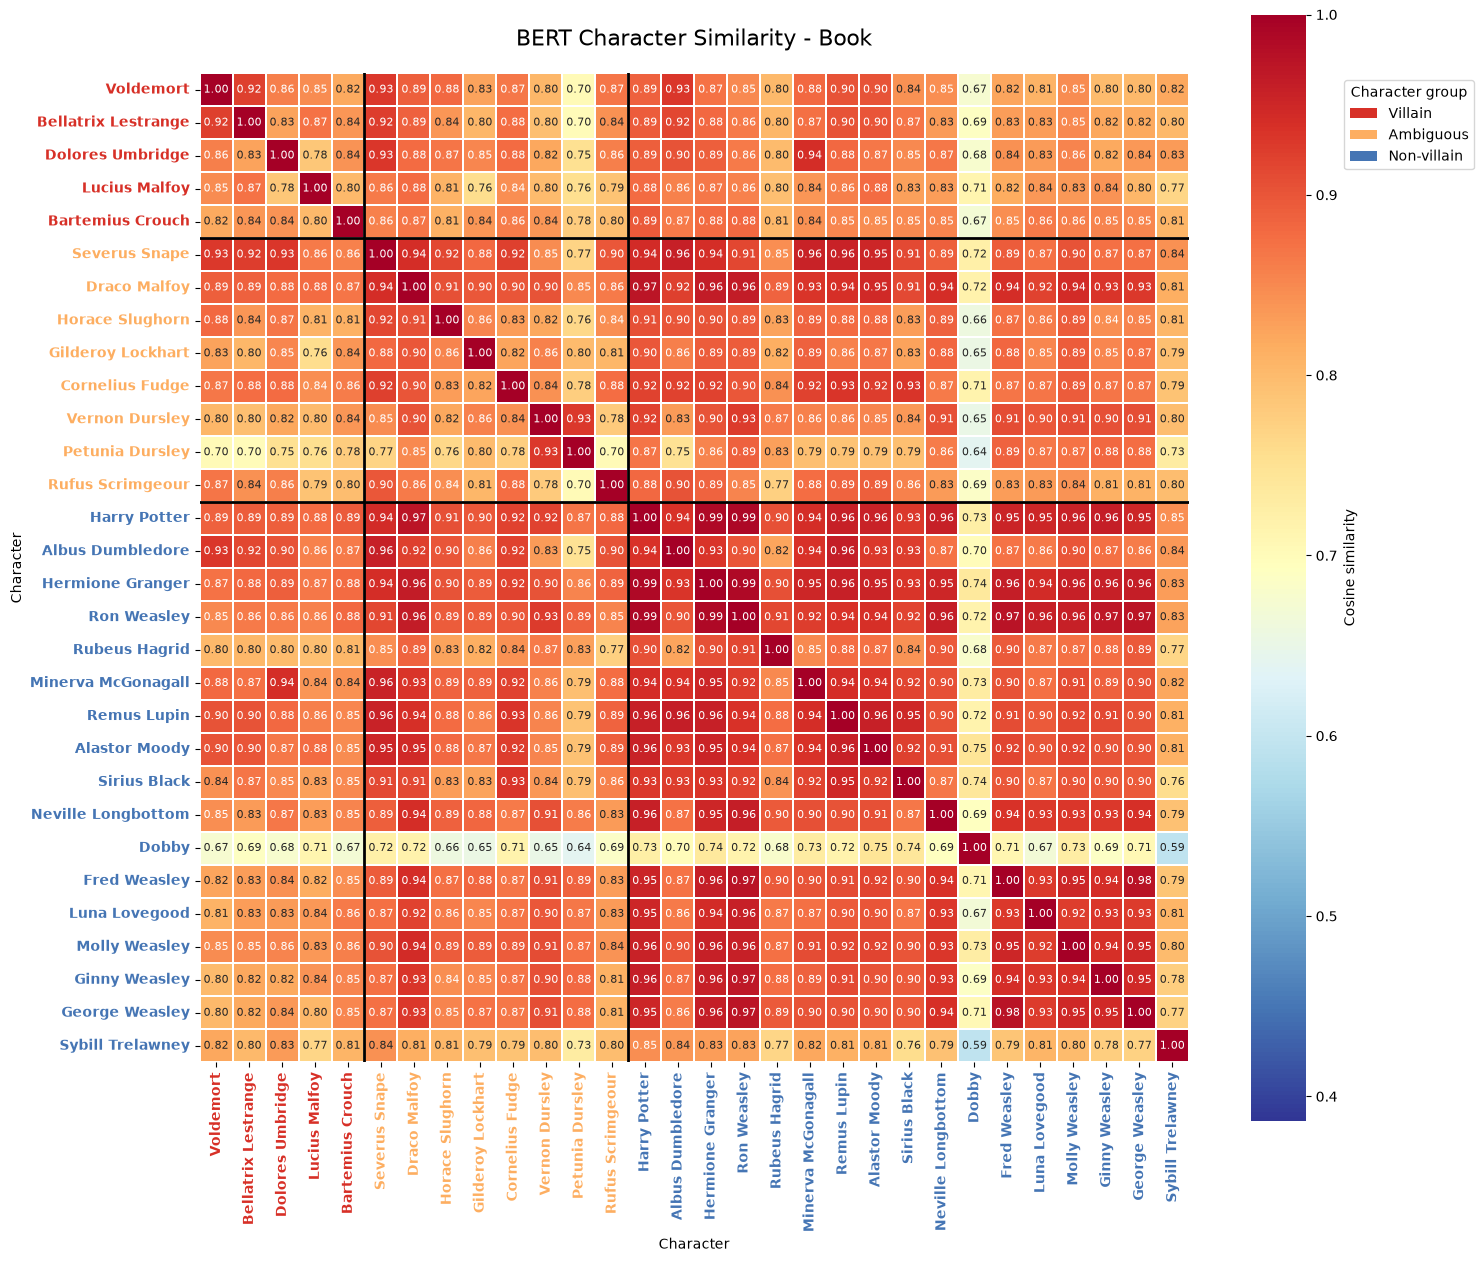

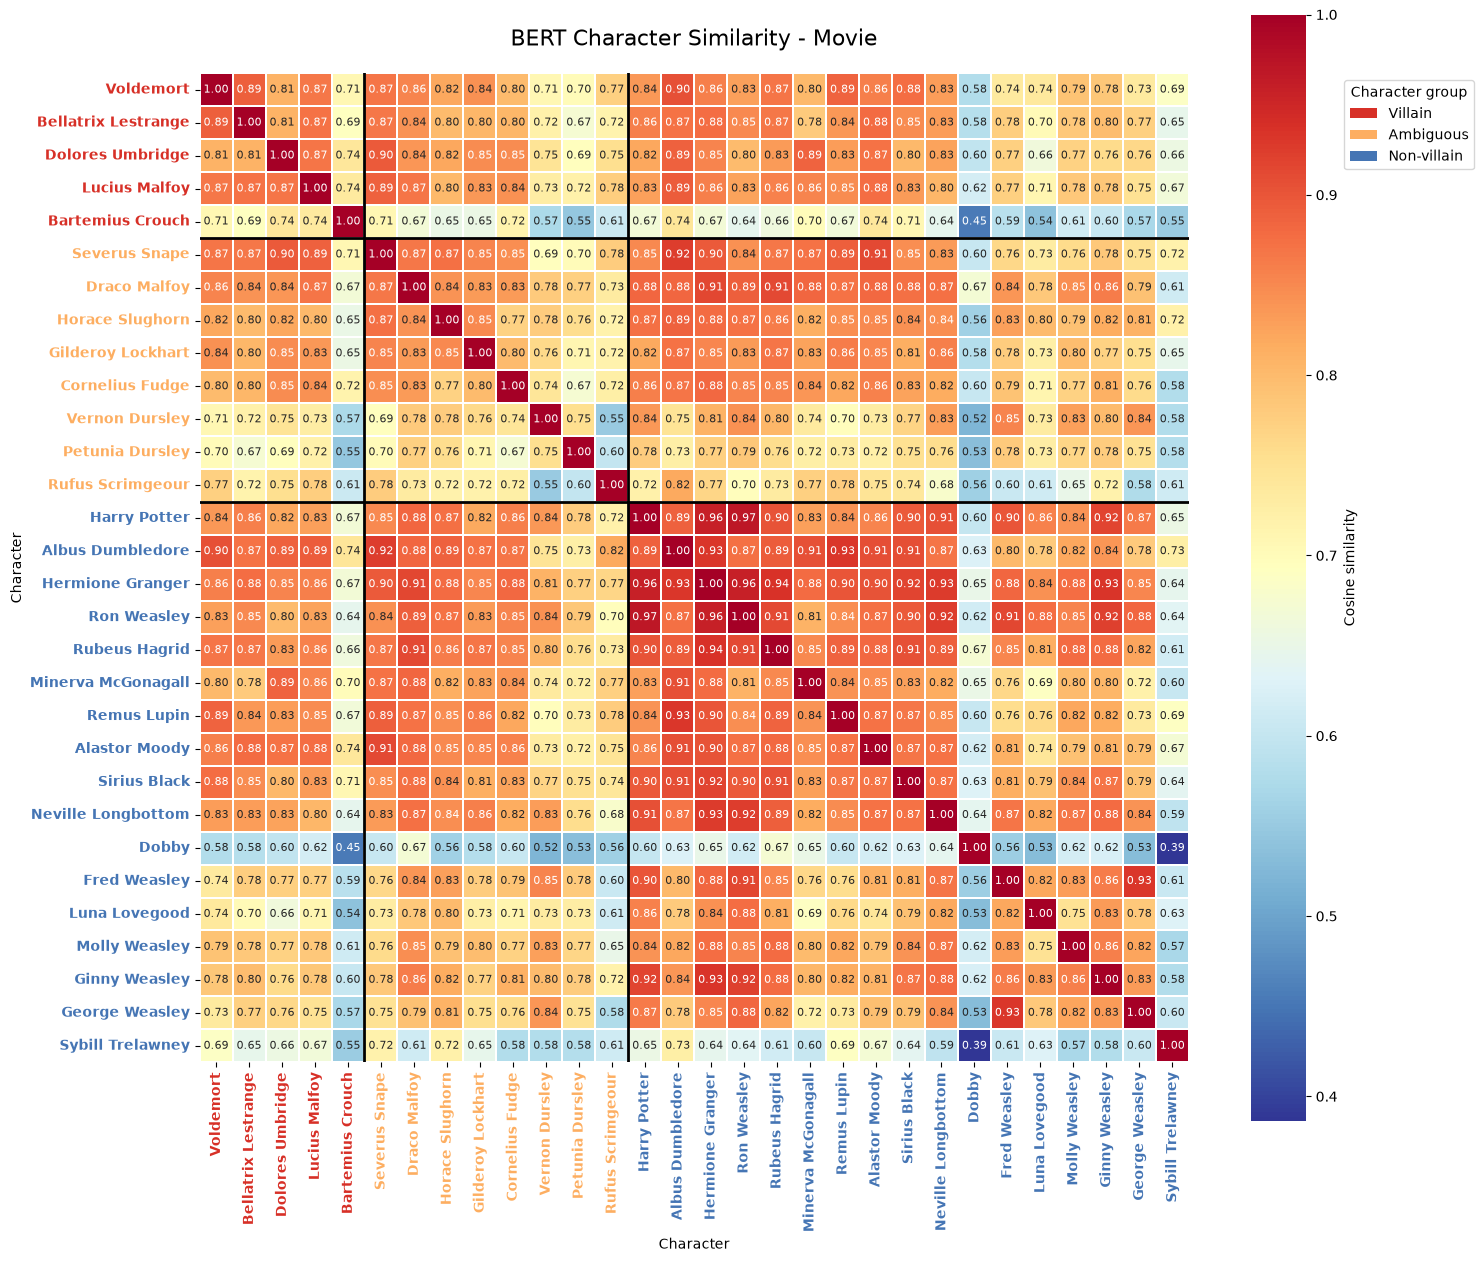

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from matplotlib.patches import Patch

# Group sizes
n_villains = len(villains)
n_ambiguous = len(ambiguous)
n_non_villains = len(non_villains)

# Colors for character groups
group_colors = {
    "Villain": "#d73027",
    "Ambiguous": "#fdae61",
    "Non-villain": "#4575b4"
}

# Color for each character
character_colors = (
    [group_colors["Villain"]] * n_villains
    + [group_colors["Ambiguous"]] * n_ambiguous
    + [group_colors["Non-villain"]] * n_non_villains
)

def plot_grouped_heatmap(similarity_df, version):

    # Reorder rows and columns
    similarity_df = similarity_df.loc[
        ordered_characters,
        ordered_characters
    ]

    fig, ax = plt.subplots(figsize=(15, 13))

    # Use the same colour range for both heatmaps
    vmin = min(book_similarity.min(), movie_similarity.min())
    vmax = max(book_similarity.max(), movie_similarity.max())

    sns.heatmap(
        similarity_df,
        cmap="RdYlBu_r",
        vmin=vmin,
        vmax=vmax,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 8},
        square=True,
        linewidths=0.3,
        ax=ax,
        cbar_kws={"label": "Cosine similarity"}
    )

    # Color tick labels according to character group
    for i, label in enumerate(ax.get_xticklabels()):
        label.set_color(character_colors[i])
        label.set_fontweight("bold")

    for i, label in enumerate(ax.get_yticklabels()):
        label.set_color(character_colors[i])
        label.set_fontweight("bold")

    # Add separating lines between groups
    boundaries = [
        n_villains,
        n_villains + n_ambiguous
    ]

    for boundary in boundaries:
        ax.axhline(boundary, color="black", linewidth=2)
        ax.axvline(boundary, color="black", linewidth=2)

    ax.set_title(
        f"BERT Character Similarity - {version.capitalize()}",
        fontsize=16,
        pad=20
    )

    ax.set_xlabel("Character")
    ax.set_ylabel("Character")

    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)

    # Legend
    legend_elements = [
        Patch(facecolor=group_colors["Villain"], label="Villain"),
        Patch(facecolor=group_colors["Ambiguous"], label="Ambiguous"),
        Patch(facecolor=group_colors["Non-villain"], label="Non-villain")
    ]

    ax.legend(
        handles=legend_elements,
        loc="upper left",
        bbox_to_anchor=(1.15, 1),
        title="Character group"
    )

    plt.tight_layout()
    plt.show()


# Plot books
plot_grouped_heatmap(book_similarity_df, "book")

# Plot movies
plot_grouped_heatmap(movie_similarity_df, "movie")

In [74]:
def compare_character_groups(similarity_df):

    def get_group_similarity(group1, group2, exclude_diagonal=False):

        values = similarity_df.loc[
            group1, group2
        ].to_numpy()

        if exclude_diagonal:
            mask = ~np.eye(len(group1), dtype=bool)
            values = values[mask]

        return values.mean()

    villain_villain = get_group_similarity(
        villains, villains, exclude_diagonal=True
    )

    nonvillain_nonvillain = get_group_similarity(
        non_villains, non_villains, exclude_diagonal=True
    )

    villain_nonvillain = get_group_similarity(
        villains, non_villains
    )

    return pd.Series({
        "Villain-Villain": villain_villain,
        "Non-villain-Non-villain": nonvillain_nonvillain,
        "Villain-Non-villain": villain_nonvillain
    })


results = pd.DataFrame({
    "Books": compare_character_groups(book_similarity_df),
    "Movies": compare_character_groups(movie_similarity_df)
})

print(results.round(3))

                         Books  Movies
Villain-Villain          0.841   0.799
Non-villain-Non-villain  0.884   0.800
Villain-Non-villain      0.842   0.763


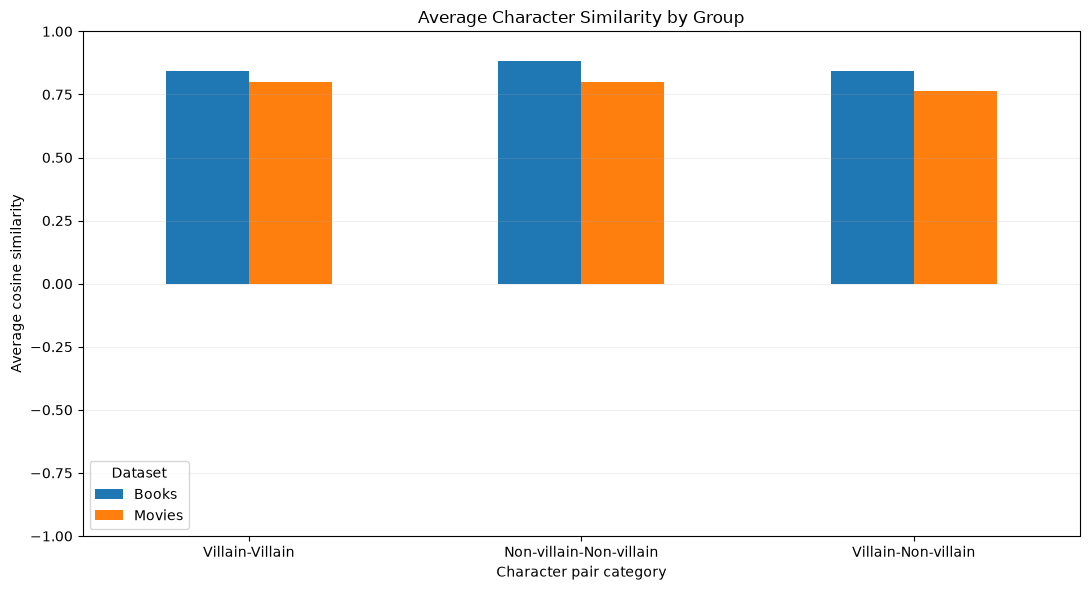

In [75]:
results.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(-1, 1),
    rot=0
)

plt.title("Average Character Similarity by Group")
plt.ylabel("Average cosine similarity")
plt.xlabel("Character pair category")
plt.legend(title="Dataset")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()